# Bump-on-tail: linear theory vs simulation
Choose a time range in the linear regime before interpreting the fitted growth rate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft
from vlasov.config import Grid
from vlasov.initial_conditions import bump_on_tail
from vlasov.numerics import compute_rho, compute_efield, cubic_interpolate
from vlasov.solver import run
from vlasov.linear_theory import dominant_mode
from vlasov.plotting import plot_growth_comparison

In [2]:
# Choose a Fourier mode compatible with the periodic spatial domain
k = 0.5
mode_number = 1
L = 2 * np.pi * mode_number / k
grid = Grid(xmin=0, xmax=L, nx=128, vmin=-8, vmax=8, nv=256)

# Equilibrium parameters
eps_bot = 0.1
t_bot = 0.1
v_bot = 3.8
perturbation = 1e-4
dt, nsteps = 0.6, 200

initial = bump_on_tail(grid, epsilon=perturbation, kx=k,
                       temperature=1.0, eps_bot=eps_bot,
                       v_bot=v_bot, t_bot=t_bot)

# Theoretical frequency (complex); root detection depends on search window
omega = dominant_mode(k, eps_bot, t_bot, v_bot)
print('Theoretical frequency:', omega)

# Solver returns (distribution history, log electric norm, mass, total energy)
f_history, log_electric_norm, mass, total_energy = run(
    initial, grid, dt, nsteps,
    interp_x=cubic_interpolate,
    interp_v=cubic_interpolate,
)
times = np.arange(nsteps + 1) * dt

Theoretical frequency: (1.4089249456061956+0.11073424173900503j)


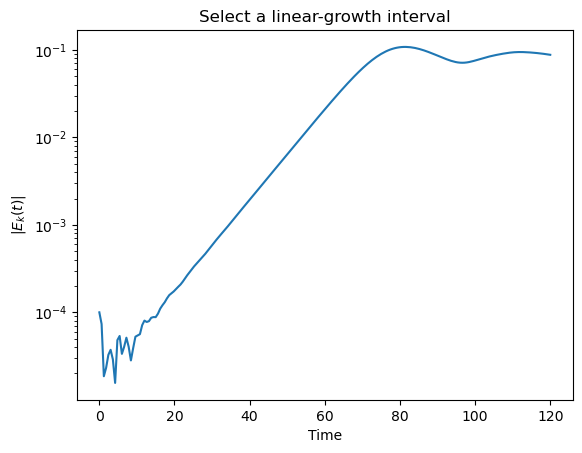

In [3]:
# Isolate the electric-field amplitude of the perturbed Fourier mode.
# This avoids mixing in other modes when determining the growth rate.
def field_mode_amplitude(f_history, grid, mode_number):
    amplitudes = np.empty(len(f_history))
    for n, f in enumerate(f_history):
        rho = compute_rho(f, grid.dv)
        efield = compute_efield(rho, grid.dx)
        amplitudes[n] = abs(fft(efield)[mode_number]) / grid.nx
    return amplitudes

amplitudes = field_mode_amplitude(f_history, grid, mode_number)
fig, ax = plt.subplots()
ax.semilogy(times, amplitudes)
ax.set(xlabel='Time', ylabel=r'$|E_k(t)|$', title='Select a linear-growth interval')
plt.show()

Theoretical growth rate: 0.11073424173900503
Measured growth rate: 0.11964252374319868


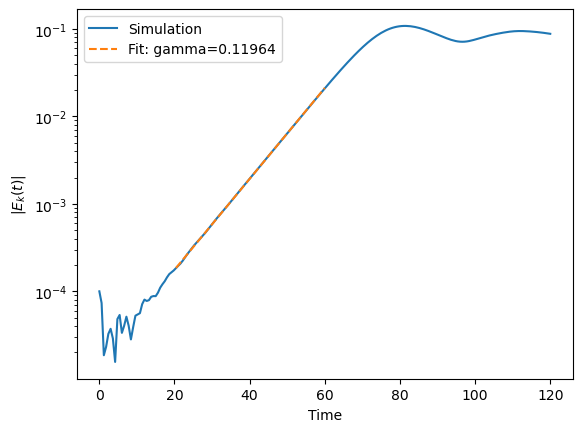

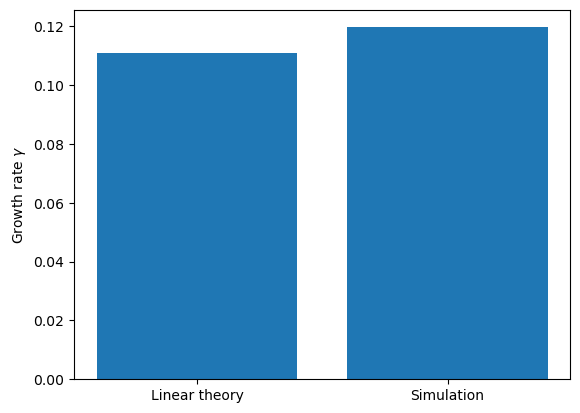

In [4]:
# Adapt this interval after checking the amplitude plot above.
tmin, tmax = 20, 60
mask = ((times >= tmin) & (times <= tmax) &
        np.isfinite(amplitudes) & (amplitudes > 0))
if mask.sum() < 3:
    raise ValueError('Insufficient positive amplitude samples in fitting window')
gamma_sim, log_amplitude0 = np.polyfit(times[mask], np.log(amplitudes[mask]), 1)
gamma_theory = None if omega is None else omega.imag
print('Theoretical growth rate:', gamma_theory)
print('Measured growth rate:', gamma_sim)

fig, ax = plt.subplots()
ax.semilogy(times, amplitudes, label='Simulation')
ax.semilogy(times[mask], np.exp(log_amplitude0 + gamma_sim * times[mask]),
            '--', label=f'Fit: gamma={gamma_sim:.5f}')
ax.set(xlabel='Time', ylabel=r'$|E_k(t)|$')
ax.legend()
plt.show()

if gamma_theory is not None:
    plot_growth_comparison(gamma_theory, gamma_sim)
    plt.show()

Simulation frequency: 1.466077


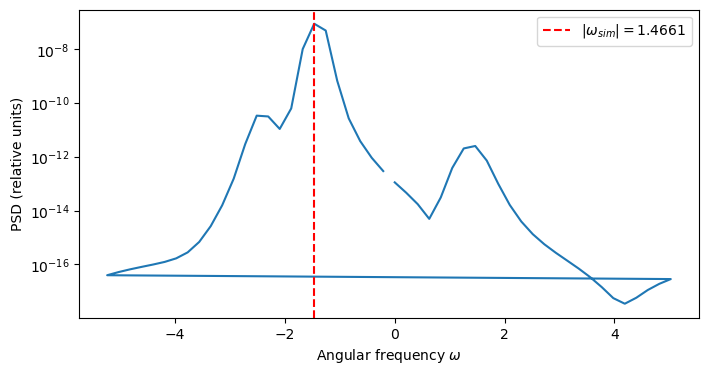

Theoretical frequency: 1.408925
Simulation frequency:  1.466077
Theoretical growth:    0.110734


In [5]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from vlasov.numerics import compute_rho, compute_efield

times = np.arange(len(f_history)) * dt

# Reconstruct E(x,t) from the saved distribution
efield_history = np.array([
    compute_efield(compute_rho(f, grid.dv), grid.dx)
    for f in f_history
])

# Extract the spatial Fourier mode closest to k
k_values = 2 * np.pi * fftfreq(grid.nx, d=grid.dx)
mode_idx = np.argmin(np.abs(k_values - k))

E_k = fft(efield_history, axis=1)[:, mode_idx] / grid.nx

# Select the linear regime
tmin, tmax = 10, 40
mask = (times >= tmin) & (times <= tmax)

t = times[mask]
signal = E_k[mask]

# Remove exponential growth/decay before computing PSD
gamma = np.polyfit(t, np.log(np.abs(signal)), 1)[0]
signal = signal * np.exp(-gamma * (t - t[0]))

# Temporal PSD of the complex spatial Fourier coefficient
window = np.hanning(len(signal))
spectrum = fft(signal * window)

omega = 2 * np.pi * fftfreq(len(signal), d=dt)
psd = np.abs(spectrum)**2 / np.sum(window**2)

# Dominant frequency (excluding the zero-frequency bin)
valid = np.abs(omega) > 1e-12
peak_idx = np.flatnonzero(valid)[np.argmax(psd[valid])]

omega_sim = abs(omega[peak_idx])

print(f"Simulation frequency: {omega_sim:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(omega, psd)
ax.axvline(omega[peak_idx], color="red", ls="--",
           label=fr"$|\omega_{{sim}}|={omega_sim:.4f}$")
ax.set_xlabel(r"Angular frequency $\omega$")
ax.set_ylabel("PSD (relative units)")
ax.set_yscale("log")
ax.legend()
plt.show()

omega_theory = dominant_mode(
    k, eps_bot, t_bot, v_bot
)

if omega_theory is not None:
    print(f"Theoretical frequency: {abs(omega_theory.real):.6f}")
    print(f"Simulation frequency:  {omega_sim:.6f}")
    print(f"Theoretical growth:    {omega_theory.imag:.6f}")